<a href="https://colab.research.google.com/github/denverkim/DM_FALL2026/blob/main/DM26_LAB6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 기본 검사

In [5]:
# 파일을 열어서 상위 5개 데이터 확인
import pandas as pd

arrest = pd.read_csv('/content/USArrests.csv')
arrest.head()

,Unnamed: 0,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0
3,Arkansas,8.8,190,50,19.5
4,California,9.0,276,91,40.6


In [6]:
# 인덱스 설정
arrest.set_index('Unnamed: 0', inplace=True)
arrest.head()

,Murder,Assault,UrbanPop,Rape
Unnamed: 0,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


In [7]:
# 데이터 사이즈 확인
arrest.shape

(50, 4)

In [11]:
# 데이터 정보
arrest.info()

<class 'pandas.core.frame.DataFrame'>
Index: 50 entries, Alabama to Wyoming
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Murder    50 non-null     float64
 1   Assault   50 non-null     int64  
 2   UrbanPop  50 non-null     int64  
 3   Rape      50 non-null     float64
dtypes: float64(2), int64(2)
memory usage: 4.0+ KB


In [12]:
# 널값 체크
arrest.isnull().sum()

,0
Murder,0
Assault,0
UrbanPop,0
Rape,0


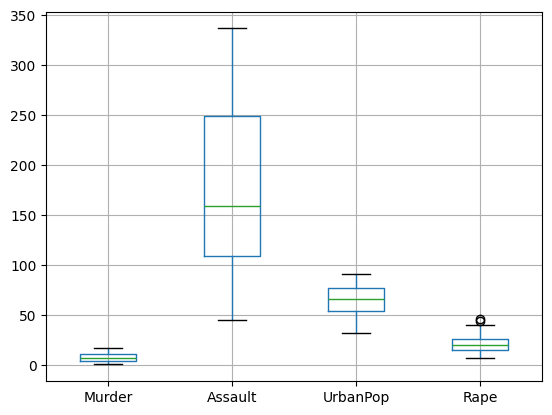

In [15]:
# 박스플랏

import matplotlib.pyplot as plt

arrest.boxplot()
plt.show()

In [17]:
# 스케일링
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(arrest)
arrest_scaled = scaler.transform(arrest)
arrest_scaled

array([[ 1.25517927,  0.79078716, -0.52619514, -0.00345116],
       [ 0.51301858,  1.11805959, -1.22406668,  2.50942392],
       [ 0.07236067,  1.49381682,  1.00912225,  1.05346626],
       [ 0.23470832,  0.23321191, -1.08449238, -0.18679398],
       [ 0.28109336,  1.2756352 ,  1.77678094,  2.08881393],
       [ 0.02597562,  0.40290872,  0.86954794,  1.88390137],
       [-1.04088037, -0.73648418,  0.79976079, -1.09272319],
       [-0.43787481,  0.81502956,  0.45082502, -0.58583422],
       [ 1.76541475,  1.99078607,  1.00912225,  1.1505301 ],
       [ 2.22926518,  0.48775713, -0.38662083,  0.49265293],
       [-0.57702994, -1.51224105,  1.21848371, -0.11129987],
       [-1.20322802, -0.61527217, -0.80534376, -0.75839217],
       [ 0.60578867,  0.94836277,  1.21848371,  0.29852525],
       [-0.13637203, -0.70012057, -0.03768506, -0.0250209 ],
       [-1.29599811, -1.39102904, -0.5959823 , -1.07115345],
       [-0.41468229, -0.67587817,  0.03210209, -0.34856705],
       [ 0.44344101, -0.

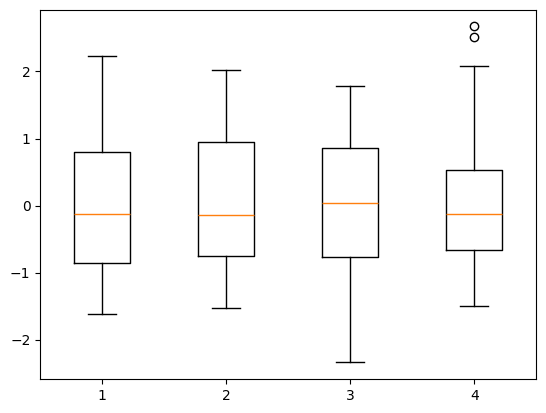

In [19]:
# 스케일링 후에 박스플랏으로 확인
plt.boxplot(arrest_scaled)
plt.show()

{'icoord': [[5.0, 5.0, 15.0, 15.0],
  [25.0, 25.0, 35.0, 35.0],
  [10.0, 10.0, 30.0, 30.0],
  [55.0, 55.0, 65.0, 65.0],
  [45.0, 45.0, 60.0, 60.0],
  [20.0, 20.0, 52.5, 52.5],
  [85.0, 85.0, 95.0, 95.0],
  [75.0, 75.0, 90.0, 90.0],
  [135.0, 135.0, 145.0, 145.0],
  [125.0, 125.0, 140.0, 140.0],
  [115.0, 115.0, 132.5, 132.5],
  [105.0, 105.0, 123.75, 123.75],
  [82.5, 82.5, 114.375, 114.375],
  [175.0, 175.0, 185.0, 185.0],
  [165.0, 165.0, 180.0, 180.0],
  [155.0, 155.0, 172.5, 172.5],
  [98.4375, 98.4375, 163.75, 163.75],
  [36.25, 36.25, 131.09375, 131.09375],
  [195.0, 195.0, 205.0, 205.0],
  [215.0, 215.0, 225.0, 225.0],
  [200.0, 200.0, 220.0, 220.0],
  [245.0, 245.0, 255.0, 255.0],
  [235.0, 235.0, 250.0, 250.0],
  [265.0, 265.0, 275.0, 275.0],
  [295.0, 295.0, 305.0, 305.0],
  [285.0, 285.0, 300.0, 300.0],
  [270.0, 270.0, 292.5, 292.5],
  [242.5, 242.5, 281.25, 281.25],
  [210.0, 210.0, 261.875, 261.875],
  [315.0, 315.0, 325.0, 325.0],
  [335.0, 335.0, 345.0, 345.0],
  [320.0

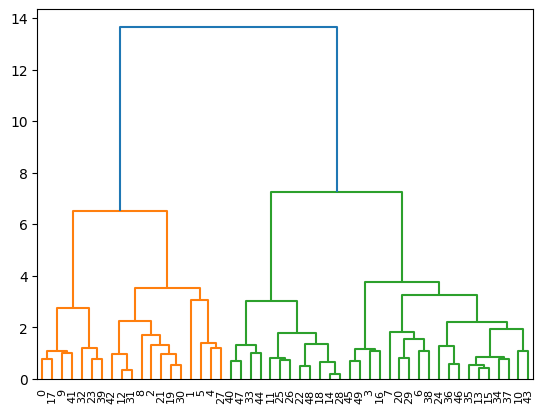

In [22]:
# 군집 갯수 결정
# 1. 댄드로그램 이용
from scipy.cluster.hierarchy import dendrogram, linkage

dendrogram(linkage(arrest_scaled, 'ward'))

In [24]:
# 2. elbow method를 이용하는 방법
from sklearn.cluster import KMeans

wss = []
k_range = range(1, 16)
for k in k_range:
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(arrest_scaled)
    total = kmeans.inertia_
    wss.append(total)
wss

[200.0,
 104.96163315756873,
 80.42914624364421,
 58.78196050521542,
 51.11258791218674,
 47.455381312800434,
 42.77212061225498,
 36.9895930661844,
 35.800232081924754,
 31.95899610808622,
 27.399928076829234,
 26.257435154011212,
 26.95859889181061,
 23.165230435779964,
 20.68924977538412]

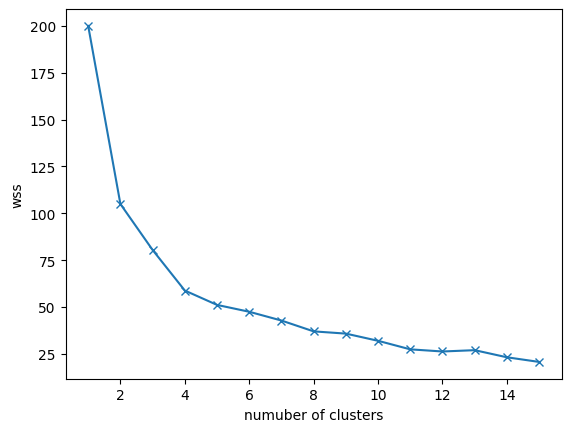

In [29]:
# elbow method 시각화
plt.plot(k_range, wss, marker='x')
plt.xlabel('numuber of clusters')
plt.ylabel('wss')
plt.show()

In [30]:
# silhouette method를 이용하는 경우
from sklearn.metrics import silhouette_score
silhouette = []
k_range = range(2, 16)
for k in k_range:
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(arrest_scaled)
    silhouette_avg = silhouette_score(arrest_scaled, kmeans.labels_)
    silhouette.append(silhouette_avg)
silhouette

[np.float64(0.4084890326217641),
 np.float64(0.36682842761846884),
 np.float64(0.23470194469271774),
 np.float64(0.2831191452709951),
 np.float64(0.3095270143302281),
 np.float64(0.2590542080264646),
 np.float64(0.25610436423970606),
 np.float64(0.23863762080329207),
 np.float64(0.22610918226030954),
 np.float64(0.2574067986858259),
 np.float64(0.24833939910351044),
 np.float64(0.21612074892686675),
 np.float64(0.2190599832290911),
 np.float64(0.19918581542736685)]

Text(0, 0.5, 'silhouette')

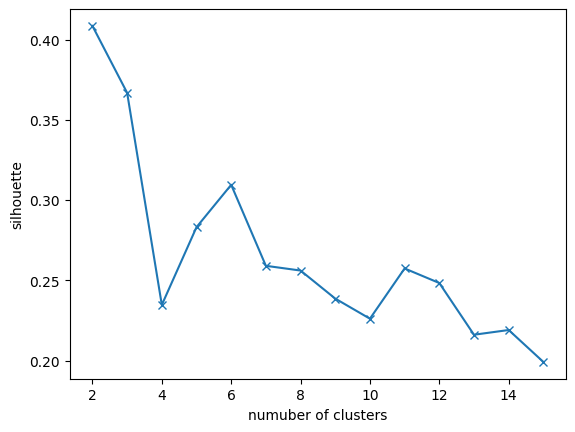

In [33]:
# silhouette graph
plt.plot(k_range,silhouette, marker='x')
plt.xlabel('numuber of clusters')
plt.ylabel('silhouette')

In [38]:
# 군집분석 알고리즘 적용
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2)
kmeans.fit(arrest_scaled)
center = kmeans.cluster_centers_
label = kmeans.labels_

In [37]:
center

array([[ 1.01513667,  1.02412028,  0.19959126,  0.85556386],
       [-0.67675778, -0.68274685, -0.13306084, -0.57037591]])

In [39]:
label

array([1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1,
       0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0], dtype=int32)

In [40]:
# 클러스터 컬럼 생성한 후 라벨 할당
arrest['cluster'] = label
arrest

,Murder,Assault,UrbanPop,Rape,cluster
Unnamed: 0,,,,,
Alabama,13.2,236,58,21.2,1
Alaska,10.0,263,48,44.5,1
Arizona,8.1,294,80,31.0,1
Arkansas,8.8,190,50,19.5,0
California,9.0,276,91,40.6,1
Colorado,7.9,204,78,38.7,1
Connecticut,3.3,110,77,11.1,0
Delaware,5.9,238,72,15.8,0
Florida,15.4,335,80,31.9,1


In [43]:
# 프로파일링
arrest.groupby('cluster').mean()

,Murder,Assault,UrbanPop,Rape
cluster,,,,
0,4.870,114.433333,63.633333,15.943333
1,12.165,255.250000,68.400000,29.165000


In [49]:
# cluster 0에 속한 주 (범죄율이 낮은 주들)
list(arrest[arrest.cluster == 0].index)

['Arkansas',
 'Connecticut',
 'Delaware',
 'Hawaii',
 'Idaho',
 'Indiana',
 'Iowa',
 'Kansas',
 'Kentucky',
 'Maine',
 'Massachusetts',
 'Minnesota',
 'Montana',
 'Nebraska',
 'New Hampshire',
 'New Jersey',
 'North Dakota',
 'Ohio',
 'Oklahoma',
 'Oregon',
 'Pennsylvania',
 'Rhode Island',
 'South Dakota',
 'Utah',
 'Vermont',
 'Virginia',
 'Washington',
 'West Virginia',
 'Wisconsin',
 'Wyoming']

In [50]:
# cluster 1에 속한 주 (범죄율이 높은 주들)
list(arrest[arrest.cluster == 1].index)

['Alabama',
 'Alaska',
 'Arizona',
 'California',
 'Colorado',
 'Florida',
 'Georgia',
 'Illinois',
 'Louisiana',
 'Maryland',
 'Michigan',
 'Mississippi',
 'Missouri',
 'Nevada',
 'New Mexico',
 'New York',
 'North Carolina',
 'South Carolina',
 'Tennessee',
 'Texas']